# <center>ML LAB - 2</center>

## Aim : To Develop a Linear Regression model for predicting house/car prices using suitable dataset.

## **Dataset:** USA Housing Dataset (`USA_Housing.csv`)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
USA_Housing = pd.read_csv('USA_Housing.csv')
USA_Housing.head()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,79545.458574,5.682861,7.009188,4.09,23086.800503,1.059034e+06,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701..."
1,79248.642455,6.002900,6.730821,3.09,40173.072174,1.505891e+06,"188 Johnson Views Suite 079\nLake Kathleen, CA..."
2,61287.067179,5.865890,8.512727,5.13,36882.159400,1.058988e+06,"9127 Elizabeth Stravenue\nDanieltown, WI 06482..."
3,63345.240046,7.188236,5.586729,3.26,34310.242831,1.260617e+06,USS Barnett\nFPO AP 44820
4,59982.197226,5.040555,7.839388,4.23,26354.109472,6.309435e+05,USNS Raymond\nFPO AE 09386


In [3]:
USA_Housing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Avg. Area Income              5000 non-null   float64
 1   Avg. Area House Age           5000 non-null   float64
 2   Avg. Area Number of Rooms     5000 non-null   float64
 3   Avg. Area Number of Bedrooms  5000 non-null   float64
 4   Area Population               5000 non-null   float64
 5   Price                         5000 non-null   float64
 6   Address                       5000 non-null   object 
dtypes: float64(6), object(1)
memory usage: 273.6+ KB


In [4]:
USA_Housing.describe()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5.000000e+03
mean,68583.108984,5.977222,6.987792,3.981330,36163.516039,1.232073e+06
std,10657.991214,0.991456,1.005833,1.234137,9925.650114,3.531176e+05
min,17796.631190,2.644304,3.236194,2.000000,172.610686,1.593866e+04
25%,61480.562388,5.322283,6.299250,3.140000,29403.928702,9.975771e+05
50%,68804.286404,5.970429,7.002902,4.050000,36199.406689,1.232669e+06
75%,75783.338666,6.650808,7.665871,4.490000,42861.290769,1.471210e+06
max,107701.748378,9.519088,10.759588,6.500000,69621.713378,2.469066e+06


In [5]:
pd.set_option('display.float_format', '{:.2f}'.format)
USA_Housing.head()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,79545.46,5.68,7.01,4.09,23086.80,1059033.56,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701..."
1,79248.64,6.00,6.73,3.09,40173.07,1505890.91,"188 Johnson Views Suite 079\nLake Kathleen, CA..."
2,61287.07,5.87,8.51,5.13,36882.16,1058987.99,"9127 Elizabeth Stravenue\nDanieltown, WI 06482..."
3,63345.24,7.19,5.59,3.26,34310.24,1260616.81,USS Barnett\nFPO AP 44820
4,59982.20,5.04,7.84,4.23,26354.11,630943.49,USNS Raymond\nFPO AE 09386


In [6]:
USA_Housing.corr(numeric_only=True)

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price
Avg. Area Income,1.00,-0.00,-0.01,0.02,-0.02,0.64
Avg. Area House Age,-0.00,1.00,-0.01,0.01,-0.02,0.45
Avg. Area Number of Rooms,-0.01,-0.01,1.00,0.46,0.00,0.34
Avg. Area Number of Bedrooms,0.02,0.01,0.46,1.00,-0.02,0.17
Area Population,-0.02,-0.02,0.00,-0.02,1.00,0.41
Price,0.64,0.45,0.34,0.17,0.41,1.00


## Data Cleaning and Exploratory Analysis

In [7]:
USA_Housing = USA_Housing.drop('Address', axis=1)
USA_Housing.head()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price
0,79545.46,5.68,7.01,4.09,23086.80,1059033.56
1,79248.64,6.00,6.73,3.09,40173.07,1505890.91
2,61287.07,5.87,8.51,5.13,36882.16,1058987.99
3,63345.24,7.19,5.59,3.26,34310.24,1260616.81
4,59982.20,5.04,7.84,4.23,26354.11,630943.49


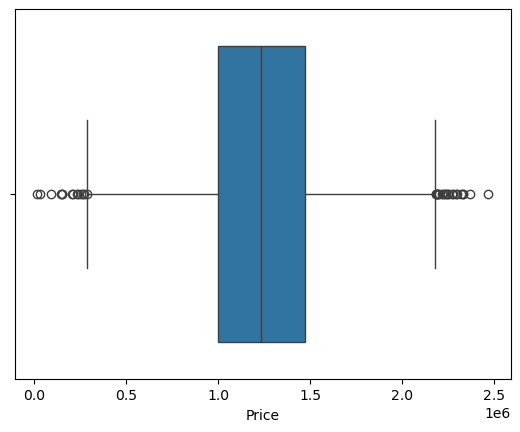

In [8]:
sns.boxplot(x=USA_Housing['Price'])
plt.show()

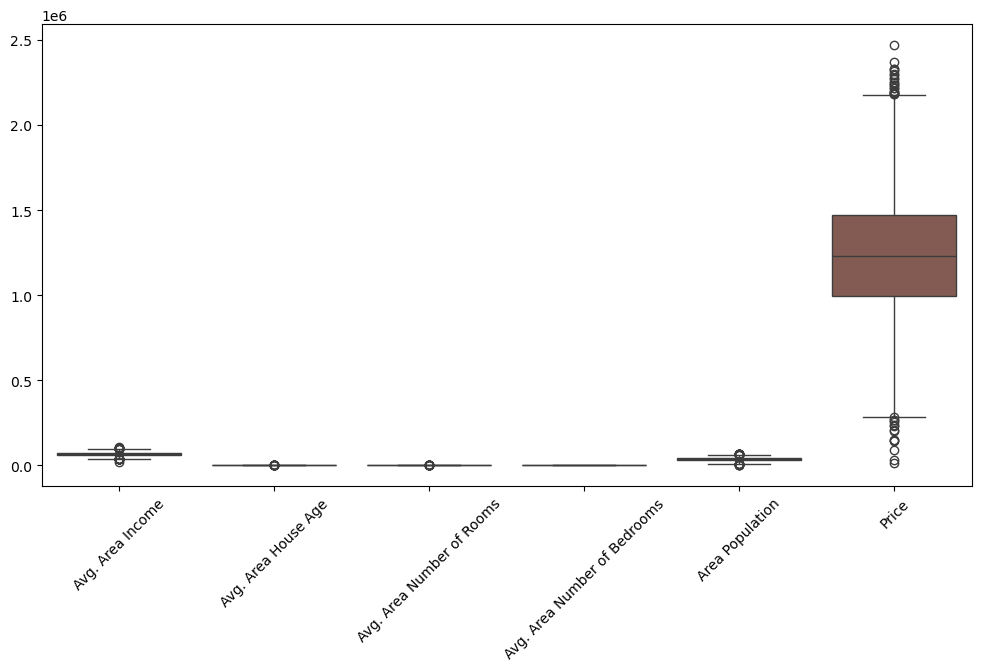

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
sns.boxplot(data=USA_Housing)
plt.xticks(rotation=45)
plt.show()

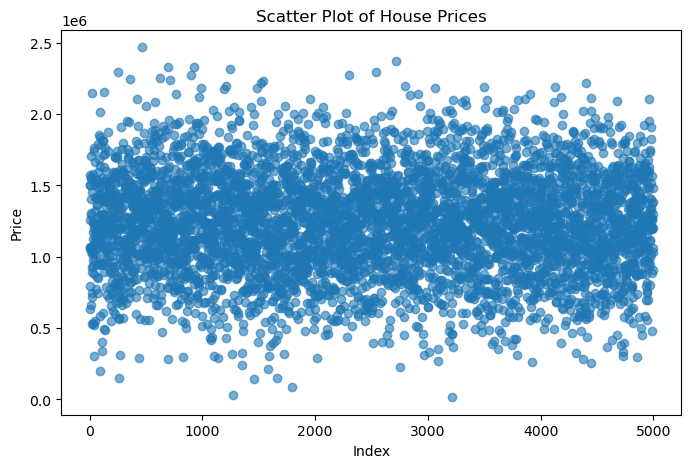

In [10]:
plt.figure(figsize=(8, 5))
plt.scatter(range(len(USA_Housing)), USA_Housing['Price'], alpha=0.6)
plt.title('Scatter Plot of House Prices')
plt.xlabel('Index')
plt.ylabel('Price')
plt.show()

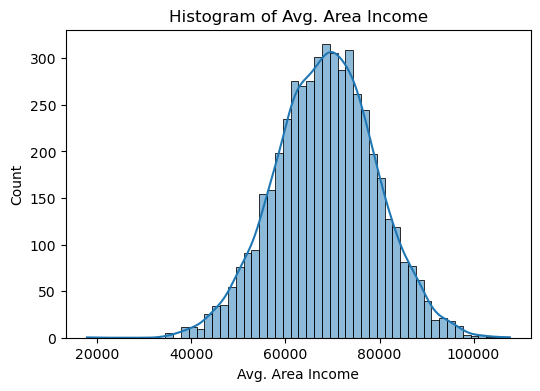

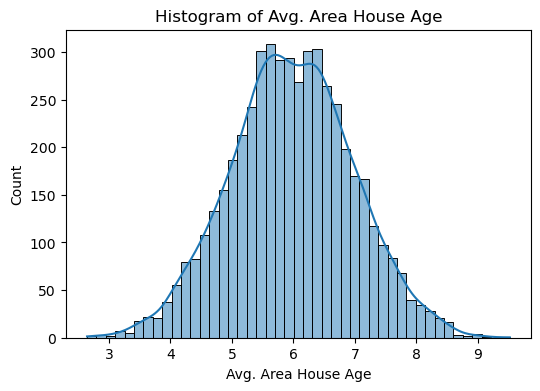

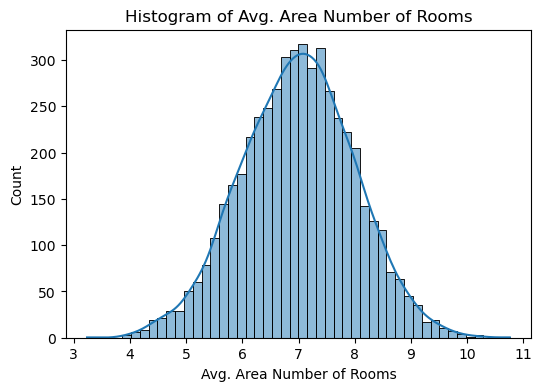

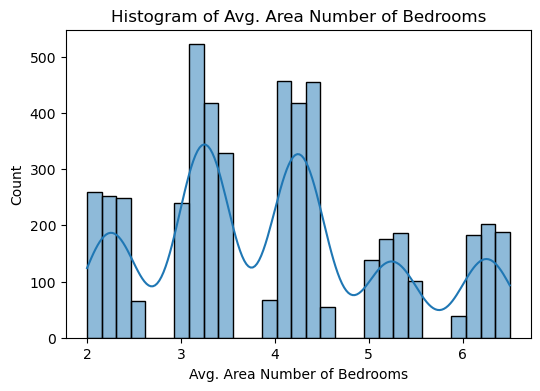

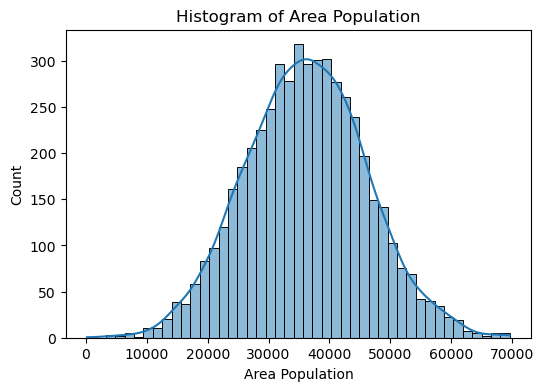

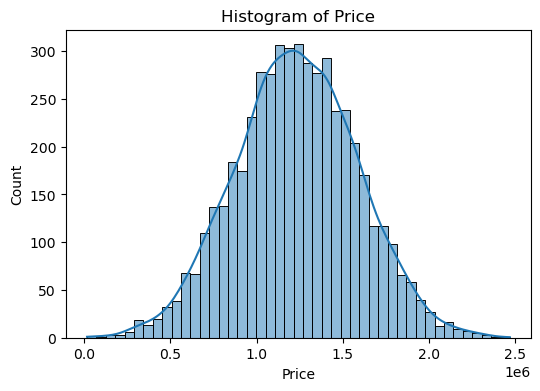

In [11]:
for col in USA_Housing.select_dtypes(include='number').columns:
    plt.figure(figsize=(6, 4))
    sns.histplot(USA_Housing[col], kde=True)
    plt.title(f'Histogram of {col}')
    plt.show()

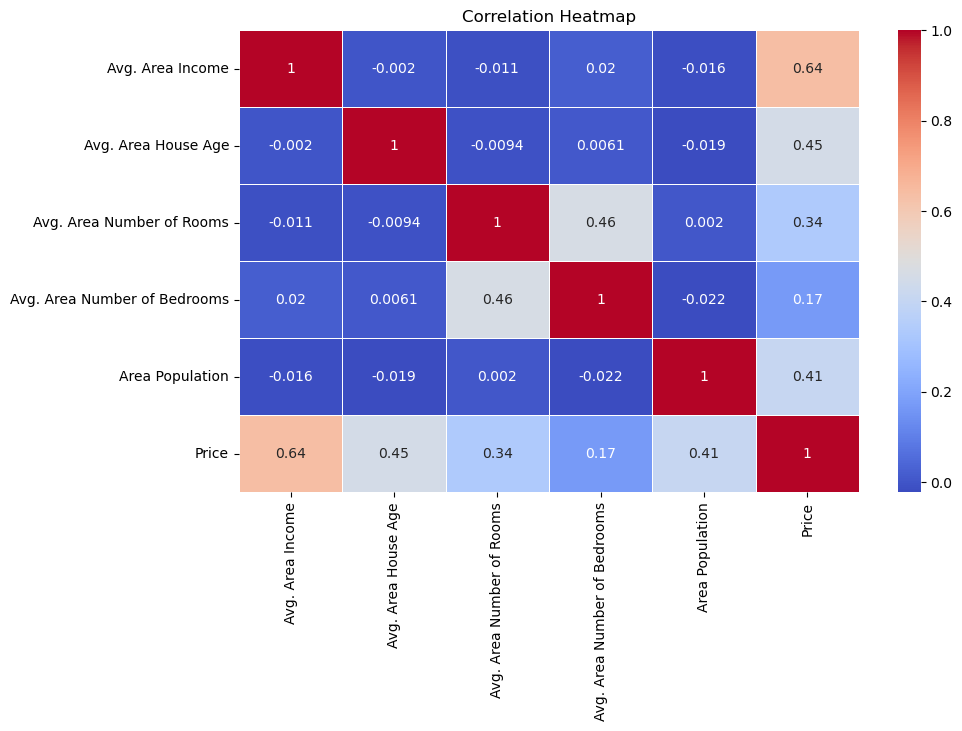

In [12]:
plt.figure(figsize=(10, 6))
corr = USA_Housing.corr(numeric_only=True)
sns.heatmap(corr, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

## Simple Linear Regression

In [47]:
X = USA_Housing[['Avg. Area Income']]
y = USA_Housing['Price']

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [48]:
from sklearn.linear_model import LinearRegression
slr_model = LinearRegression()
slr_model.fit(X_train, y_train)

LinearRegression()

In [49]:
y_pred = slr_model.predict(X_test)

In [50]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nModel Evaluation")
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)


Model Evaluation
MAE : 216826.3530998906
MSE : 74194887058.66
RMSE: 272387.38417676394
R2 Score: 0.39694865192619766


In [51]:
results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

In [52]:
print(results.head())

         Actual  Predicted
1501 1339096.08 1087938.64
2586 1251794.18  987251.67
2653 1340094.97 1263616.32
1055 1431507.62 1245079.75
705  1042373.52 1323015.79


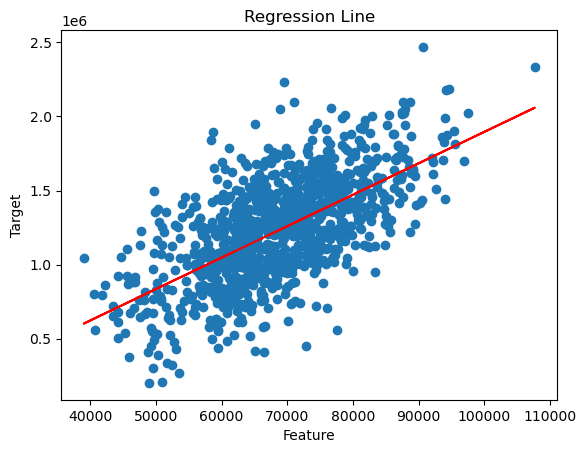

In [53]:
plt.scatter(X_test, y_test)
plt.plot(X_test, y_pred, color="red")
plt.xlabel("Feature")
plt.ylabel("Target")
plt.title("Regression Line")
plt.show()

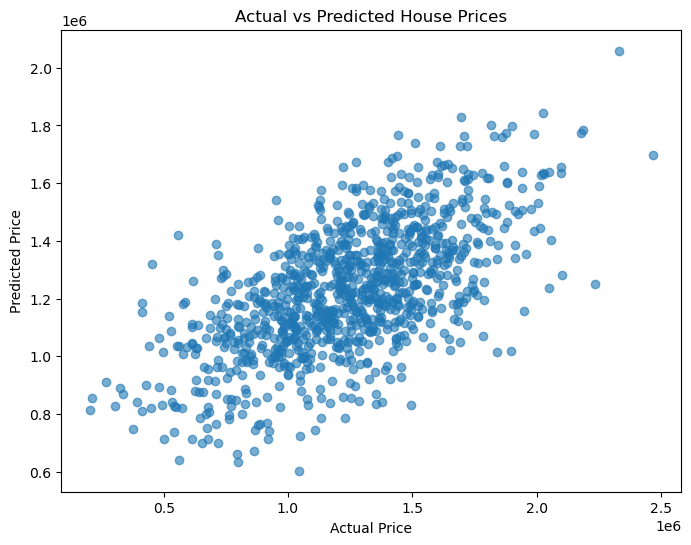

In [54]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")
plt.show()

In [57]:
lm = LinearRegression()

In [58]:
lm.fit(X_train, y_train)

LinearRegression()

In [59]:
print(lm.intercept_)

-225053.70287170215


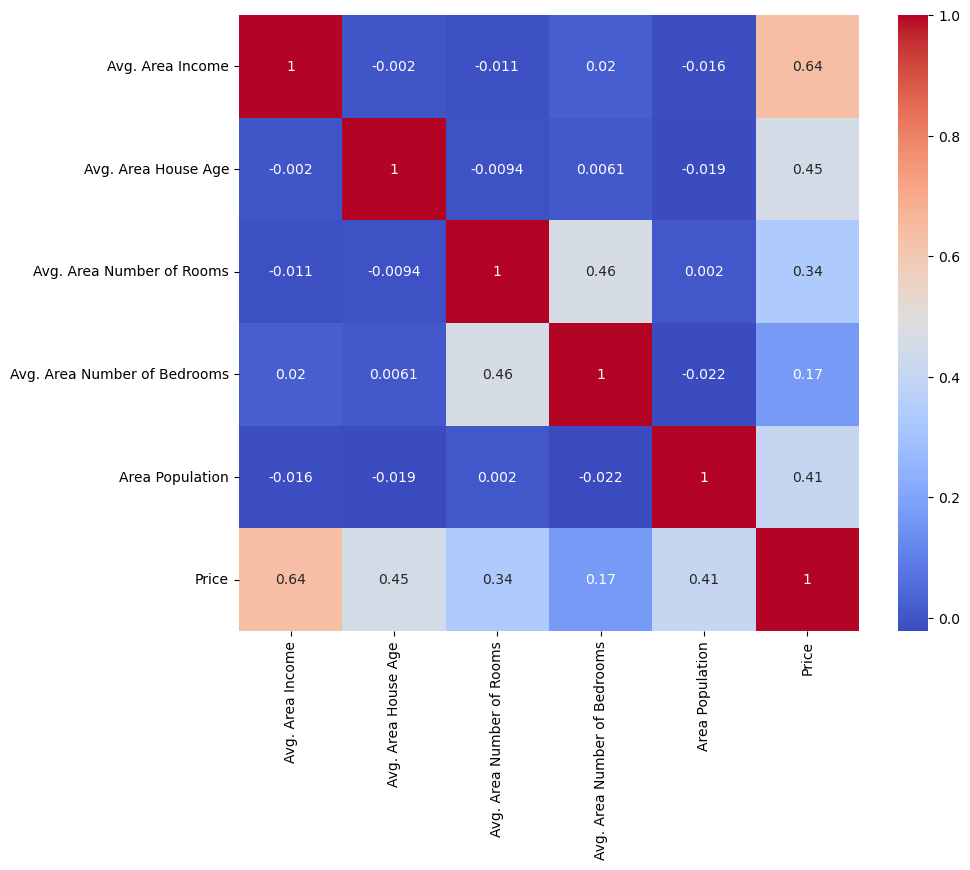

In [56]:
plt.figure(figsize=(10, 8))
sns.heatmap(
    USA_Housing.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)
plt.show()

## Multiple Linear Regression

In [69]:
USA_Housing.corr(numeric_only=True)['Price'].sort_values(ascending=False)

Price                          1.00
Avg. Area Income               0.64
Avg. Area House Age            0.45
Area Population                0.41
Avg. Area Number of Rooms      0.34
Avg. Area Number of Bedrooms   0.17
Name: Price, dtype: float64

In [70]:
X = USA_Housing.drop(["Price"], axis=1)
y = USA_Housing["Price"]

In [71]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [73]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [74]:
y_pred = model.predict(X_test)

In [75]:
print("Intercept:", model.intercept_)
print("Coefficients:")
print(pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
}))

Intercept: -2635072.900932907
Coefficients:
                        Feature  Coefficient
0              Avg. Area Income        21.65
1           Avg. Area House Age    164666.48
2     Avg. Area Number of Rooms    119624.01
3  Avg. Area Number of Bedrooms      2440.38
4               Area Population        15.27


In [76]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 80879.09723489163
MSE: 10089009300.89364
RMSE: 100444.06055558308
R2 Score: 0.917997170683436


# Ridge Regression

In [77]:
from sklearn.model_selection import GridSearchCV

In [78]:
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score

ridge = Ridge()
ridge.fit(X_train, y_train)
ridge_pred = ridge.predict(X_test)

In [79]:
print("Default Ridge R^2 Score :",r2_score(y_test,ridge_pred))

Default Ridge R^2 Score : 0.91799142202412


In [80]:
param_grid = {
    'alpha': [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

In [81]:
grid_ridge = GridSearchCV(
    estimator=ridge,
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)
grid_ridge.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=Ridge(), n_jobs=-1,
             param_grid={'alpha': [0.001, 0.01, 0.1, 1, 10, 100, 1000]},
             scoring='r2')

In [82]:
print("Best Alpha:", grid_ridge.best_params_)

Best Alpha: {'alpha': 1}


In [83]:
print(grid_ridge.best_score_)

0.9174133082098411


In [84]:
print("Best Alpha:",grid_ridge.best_params_)
print("Best Cross Validation R2:", grid_ridge.best_score_)

Best Alpha: {'alpha': 1}
Best Cross Validation R2: 0.9174133082098411


In [85]:
best_ridge = grid_ridge.best_estimator_
ridge_pred = best_ridge.predict(X_test)
print("Test R2 Score:", r2_score(y_test, ridge_pred))

Test R2 Score: 0.91799142202412


## Lasso Regression

In [86]:
from sklearn.linear_model import Lasso
param_grid = {
    'alpha': [0.001, 0.01, 0.1, 1, 10]
}

In [87]:
grid_lasso = GridSearchCV(
    Lasso(max_iter=5000),
    param_grid,
    cv=5,
    scoring='r2'
)

grid_lasso.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=Lasso(max_iter=5000),
             param_grid={'alpha': [0.001, 0.01, 0.1, 1, 10]}, scoring='r2')

In [88]:
print(grid_lasso.best_params_)

{'alpha': 10}


In [89]:
lasso_pred = grid_lasso.predict(X_test)
print(r2_score(y_test, lasso_pred))

0.9179961853521253


In [90]:
predictions = model.predict(X_test)

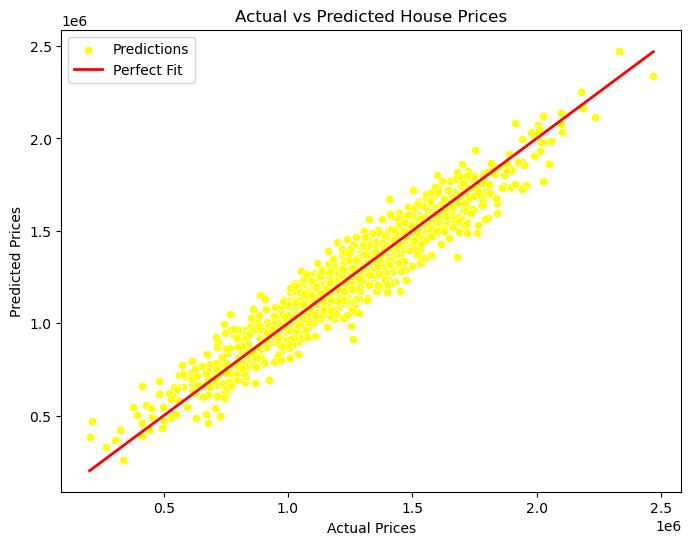

In [91]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=y_test,
    y=predictions,
    color='yellow',
    label='Predictions'
)

# Add a reference line (perfect prediction line)
plt.plot(
    [min(y_test), max(y_test)],
    [min(y_test), max(y_test)],
    color='red',
    linewidth=2,
    label='Perfect Fit'
)

plt.title('Actual vs Predicted House Prices')
plt.xlabel('Actual Prices')
plt.ylabel('Predicted Prices')
plt.legend()
plt.show()